# Layer 6 in practice: the covariance of a data vector

This notebook executes the material of {doc}`../layer6_covariance`: the
covariance of a joint $w_p(r_p)$ and $\Delta\Sigma(R)$ vector of an LS10-like
galaxy sample, term by term, its correlation matrix, and the Gaussian
covariance of an angular spectrum.
It runs on a `pip install` of `ggah_mod` plus `matplotlib`, in about two minutes.
Layers 3 to 6 are work in progress, and the notice they emit on import is silenced below.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)   # before the first ggah_mod import

import warnings

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import ggah_mod
warnings.filterwarnings("ignore", category=ggah_mod.WorkInProgressWarning)

import ggah_mod.covariance as CV
import ggah_mod.observables as OB
import ggah_mod.sectors as S
from ggah_mod import DIFFERENTIABLE
from ggah_mod.cosmology import PLANCK18, make_pk
from ggah_mod.halos.calibration import MismatchWarning
from ggah_mod.halos.field import make_field, make_fields

warnings.filterwarnings("ignore", category=MismatchWarning)
plt.rcParams.update({"figure.dpi": 90, "figure.figsize": (6.4, 4.0),
                     "axes.grid": True, "grid.alpha": 0.3})
print(f"ggah_mod {ggah_mod.__version__}, jax {jax.__version__}")

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


ggah_mod 1.7.0, jax 0.10.2


## The sample and the data vector

`zumandelbaum15` at its defaults, at $z = 0.13$, on the footprint of the LS10
sample above $10^{10}\,{\rm M}_\odot$ drawn as a disc of the same area (the
super-sample term needs a mask), and a $400\,{\rm deg}^2$ disc for the overlap
with an illustrative source sample.
The vector is $w_p$ at $\pi_{\max} = 67.4\,h^{-1}{\rm Mpc}$ and $\Delta\Sigma$,
in the same five bins of $r_p$.

In [2]:
pk = make_pk("emu_pk")
Z = 0.13
gal, gp = S.GalaxySector("zumandelbaum15", calibration="off"), S.galaxy_defaults("zumandelbaum15")
field = make_field(PLANCK18, DIFFERENTIABLE, pk, z=Z)
f_cen, _ = gal.stellar_fraction(field, gp)
split = S.BaryonSplit.from_hot(S.cosmic_baryon_fraction(PLANCK18), jnp.full(field.n_m, 0.1),
                               f_star_cen=f_cen)
sectors = {"galaxies": gal, "matter": S.MatterField()}
params = {"galaxies": gp, "matter": {"split": split}}
fields_at = lambda zs: make_fields(PLANCK18, DIFFERENTIABLE, pk, zs)

edges = np.logspace(-1.0, 1.0, 6)
rp = np.sqrt(edges[1:] * edges[:-1])
spec = OB.ObservableSpec((OB.Wp("wp", "galaxies", "galaxies", rp, pi_max=67.4, z=Z),
                          OB.DeltaSigma("ds", "galaxies", "matter", rp, z=Z)))
area = CV.ls10_sample("10.0")
geo = CV.spherical_cap(area.area_sr / (4 * np.pi), name="LS10 disc",
                       z_min=area.z_min, z_max=area.z_max, ell_max=1024)
overlap = CV.spherical_cap(400.0 / CV.FULL_SKY_DEG2, name="lensing overlap",
                           z_min=area.z_min, z_max=area.z_max, ell_max=2048)
nbar = float(gal.number_density(field, gp))
src = CV.SourceSample("sources", 5e15, 0.28, 15.0, 700.0, 134.8, None, "illustrative")
common = dict(geometry=geo, edges={"wp": edges, "ds": edges}, fields_at=fields_at,
              sectors=sectors, cosmo=PLANCK18, backend=DIFFERENTIABLE,
              tracer_noise={"galaxies": 1.0 / nbar}, sources={"ds": src},
              lensing_geometry=overlap)
print(f"{geo.area_deg2:.0f} deg^2, {area.z_min} < z < {area.z_max}, "
      f"V = {float(geo.volume(PLANCK18)):.2e} h^-3 Mpc^3, n = {nbar:.2e} h^3 Mpc^-3")

18974 deg^2, 0.05 < z < 0.18, V = 2.59e+08 h^-3 Mpc^3, n = 5.22e-03 h^3 Mpc^-3


## Term by term

The diagonal of each term, divided by that of the Gaussian term, for *(a)* $w_p$
and *(b)* $\Delta\Sigma$.

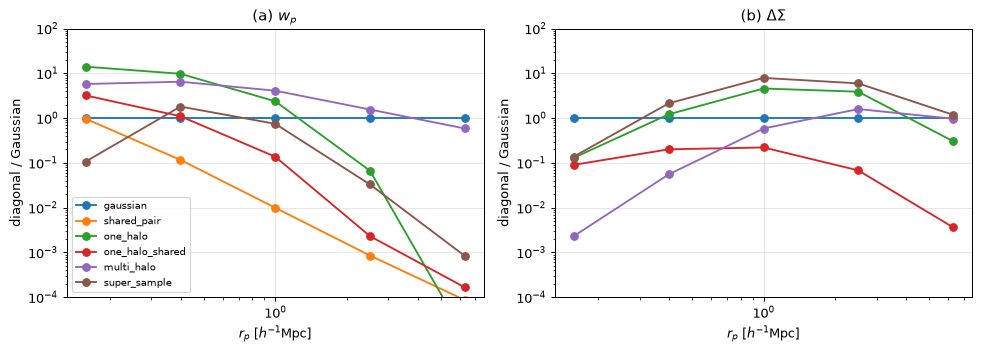

In [3]:
parts = {t: np.asarray(CV.covariance(spec, terms=(t,), **common)(params)) for t in CV.TERMS}
g = np.diag(parts["gaussian"])

fig, ax = plt.subplots(1, 2, figsize=(11.0, 4.0))
for i, (t, c) in enumerate(parts.items()):
    d = np.diag(c) / g
    ax[0].loglog(rp, np.maximum(d[:5], 1e-6), f"C{i}o-", label=t)
    ax[1].loglog(rp, np.maximum(d[5:], 1e-6), f"C{i}o-")
for a, t in zip(ax, (r"(a) $w_p$", r"(b) $\Delta\Sigma$")):
    a.set(xlabel=r"$r_p\ [h^{-1}{\rm Mpc}]$", ylabel="diagonal / Gaussian", ylim=(1e-4, 1e2), title=t)
ax[0].legend(fontsize=8)
for a in ax:
    a.xaxis.set_minor_formatter(plt.NullFormatter())
fig.tight_layout()

## The correlation matrix

The correlation matrix of the Gaussian term and of every term together; the
first five rows are $w_p$, the last five $\Delta\Sigma$.
The terms add, so the full covariance is the sum of the parts above.

max |sum of the parts - total| / max |total| = 8.7e-17
error over its Gaussian part: [5.01 4.5  2.89 1.63 1.26 1.17 2.15 3.78 3.53 1.86]


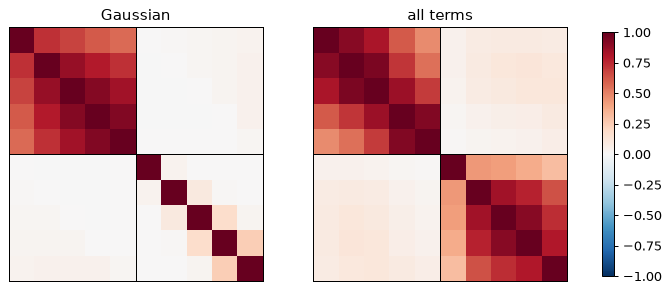

In [4]:
total = sum(parts.values())
print(f"max |sum of the parts - total| / max |total| = "
      f"{np.max(np.abs(total - np.asarray(CV.covariance(spec, terms=tuple(CV.TERMS), **common)(params)))) / np.max(np.abs(total)):.1e}")

def corr(c):
    s = np.sqrt(np.diag(c))
    return c / np.outer(s, s)

fig, ax = plt.subplots(1, 2, figsize=(10.0, 4.4))
for a, c, t in zip(ax, (parts["gaussian"], total), ("Gaussian", "all terms")):
    im = a.imshow(corr(c), vmin=-1, vmax=1, cmap="RdBu_r")
    a.axhline(4.5, color="k", lw=0.8); a.axvline(4.5, color="k", lw=0.8)
    a.set(title=t, xticks=[], yticks=[])
fig.colorbar(im, ax=ax, shrink=0.8)
print("error over its Gaussian part:", np.round(np.sqrt(np.diag(total) / g), 2))

## The Gaussian covariance of an angular spectrum

The Gaussian covariance of the galaxy angular spectrum of a sample at
$z \simeq 0.5$ over the sky above $|b| = 20^\circ$, with the shot noise of
$10^{-6}$ per steradian, against the cosmic variance alone.

f_sky = 0.658


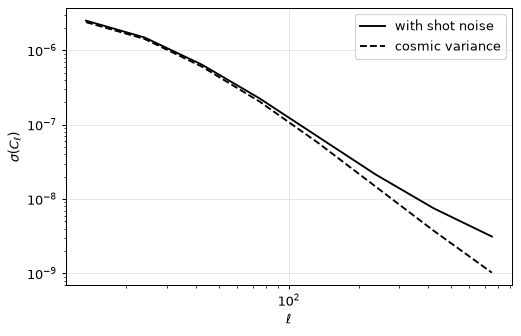

In [5]:
z, chi = OB.limber_grid(PLANCK18, z_max=1.0, n=16, backend=DIFFERENTIABLE)
kernels = {"counts": OB.number_counts(z, chi, np.exp(-0.5 * ((np.asarray(z) - 0.5) / 0.1) ** 2))}
ell_edges = np.unique(np.round(np.logspace(1, 3, 9)).astype(int))
ell = np.sqrt(ell_edges[1:] * ell_edges[:-1])
cl_spec = OB.ObservableSpec((OB.Cl("cl", "galaxies", "galaxies", ell,
                                   kernel_a="counts", kernel_b="counts"),))
sky = CV.galactic_latitude_cut(20.0, ell_max=16)
kw = dict(geometry=sky, edges={"cl": ell_edges}, fields_at=fields_at, sectors=sectors,
          kernels=kernels, cosmo=PLANCK18, backend=DIFFERENTIABLE, z_proj=np.asarray(z))
c_noise = np.asarray(CV.gaussian_covariance(cl_spec, cl_noise={("galaxies", "counts"): 1e-6}, **kw)(params))
c_cv = np.asarray(CV.gaussian_covariance(cl_spec, cl_noise={("galaxies", "counts"): 0.0}, **kw)(params))
fig, ax = plt.subplots()
ax.loglog(ell, np.sqrt(np.diag(c_noise)), "k", label="with shot noise")
ax.loglog(ell, np.sqrt(np.diag(c_cv)), "k--", label="cosmic variance")
ax.set(xlabel=r"$\ell$", ylabel=r"$\sigma(C_\ell)$")
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.legend()
print(f"f_sky = {sky.f_sky:.3f}")

## Things to try

- Swap the disc for `CV.ls10_sample("10.0")`, which carries the area alone, and
  read the refusal of the super-sample term.
- Pass `wp_sigma_los={"wp": 40.0}` for a photometric $w_p$ and compare the
  one-halo term.
- Double the source density of `SourceSample` and follow the $\Delta\Sigma$
  errors.

Previous: {doc}`layer5_observables`.